# Steam Game Review Prediction
Predicting a Steam game's overall review class (Positive / Mixed / Negative) from Steam store information that is mostly known at release. Machine Learning course project, built in Google Colab.

**Dataset:** `steam-games.csv` (42,497 rows x 24 columns; 40,020 usable after dropping rows with no review label).

**Dataset source:** Steam Games sales Dataset, Kaggle (author: armaanmanwatkar), https://www.kaggle.com/datasets/armaanmanwatkar/steam-games-sales-dataset (file used: `steam-games.csv`). License: MIT. Accessed 14 Oct 2026.

## How to run this notebook
- **Normal run:** go top to bottom, but **skip the optional grid searches in Section 5b** (over an hour). Their best settings are already stored in the cell just above them.
- **After a Colab disconnect:** do **not** use "Run all". Run only **Section 9 (Restore)**, then Sections 6b and 8 if you need the extra evaluation or the live demo.
- **Never rerun Section 7 (Save bundle) after a disconnect.** It would overwrite the saved bundle in Drive.

| Section | Content |
|---|---|
| 0 | Setup |
| 1 | Phase 1: Data understanding |
| 2 | Phase 2: Exploratory data analysis |
| 3 | Phase 3: Preprocessing |
| 4 | Phase 4: Baselines |
| 5 | Phase 5: Model building and tuning |
| 6 | Phase 6: Evaluation and comparison (6b: extra evaluation) |
| 7 | Save bundle |
| 8 | Live demo |
| 9 | Restore after disconnect |
| 10 | Final answers |

## Problem Statement
Predict whether a Steam game's overall review will be **Positive, Mixed or Negative**, using store information that is mostly known around release.
Studios can't know before launch how players will react. An early estimate helps them spot risk, and gives players a quick signal about new games. Some features (awards, DLC, some tags) can be added after launch; this is a limitation.

## Objectives
1. Build 5 models and compare them with 2 baselines.
2. Handle class imbalance and avoid data leakage.
3. Find which features matter most.

## Target, Features, Problem Type
- **Target:** review_class: Positive 72.2%, Mixed 23.7%, Negative 4.1% (merged from Steam's 9 review levels)
- **Features:** 11 store features: price, release year, genres, categories, DLC, awards, age rating, Mac, Linux, developer, publisher
- **Type:** multi-class classification on imbalanced data

## Project Questions
Q1. Can store information predict the review class better than a baseline?
Q2. Which of the 5 models is best (macro F1, ROC-AUC, PR-AUC)?
Q3. Which features matter most?

## 0. Setup
*Mount Google Drive, import the libraries and print their versions.*

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = '/content/drive/MyDrive/Colab Notebooks/ML_Project/steam-games.csv'
FIG_DIR = '/content/drive/MyDrive/Colab Notebooks/ML_Project/figures'
os.makedirs(FIG_DIR, exist_ok=True)

import sklearn, xgboost, seaborn, matplotlib
print('Python', sys.version.split()[0])
for lib in (np, pd, sklearn, xgboost, matplotlib, seaborn):
    print(lib.__name__, lib.__version__)

Mounted at /content/drive
Python 3.13.18
numpy 2.4.6
pandas 2.2.3
sklearn 1.6.1
xgboost 3.4.1
matplotlib 3.10.0
seaborn 0.13.2


## 1. Phase 1: Data Understanding
*Load the data and take a first look: size, column types, missing values, duplicates and the target.*

In [2]:
df = pd.read_csv(DATA_PATH)

In [3]:
df.shape

(42497, 24)

In [4]:
df.columns.tolist()

['app_id',
 'title',
 'release_date',
 'genres',
 'categories',
 'developer',
 'publisher',
 'original_price',
 'discount_percentage',
 'discounted_price',
 'dlc_available',
 'age_rating',
 'content_descriptor',
 'about_description',
 'win_support',
 'mac_support',
 'linux_support',
 'awards',
 'overall_review',
 'overall_review_%',
 'overall_review_count',
 'recent_review',
 'recent_review_%',
 'recent_review_count']

In [5]:
df.head(10)

,app_id,title,release_date,genres,categories,developer,publisher,original_price,discount_percentage,discounted_price,...,win_support,mac_support,linux_support,awards,overall_review,overall_review_%,overall_review_count,recent_review,recent_review_%,recent_review_count
0,730,Counter-Strike 2,"21 Aug, 2012","Action, Free to Play","Cross-Platform Multiplayer, Steam Trading Card...",Valve,Valve,NaN,NaN,Free,...,True,False,True,1,Very Positive,87.0,8062218.0,Mostly Positive,79.0,57466.0
1,570,Dota 2,"9 Jul, 2013","Action, Strategy, Free to Play","Steam Trading Cards, Steam Workshop, SteamVR C...",Valve,Valve,NaN,NaN,Free,...,True,True,True,0,Very Positive,81.0,2243112.0,Mostly Positive,72.0,23395.0
2,2215430,Ghost of Tsushima DIRECTOR'S CUT,"16 May, 2024","Action, Adventure","Single-player, Online Co-op, Steam Achievement...",Sucker Punch Productions,PlayStation PC LLC,NaN,NaN,"₹3,999.00",...,True,False,False,0,Very Positive,89.0,12294.0,NaN,NaN,NaN
3,1245620,ELDEN RING,"24 Feb, 2022","Action, RPG","Single-player, Online PvP, Online Co-op, Steam...",FromSoftware Inc.,FromSoftware Inc.,NaN,NaN,"₹3,599.00",...,True,False,False,6,Very Positive,93.0,605191.0,Very Positive,94.0,7837.0
4,1085660,Destiny 2,"1 Oct, 2019","Action, Adventure, Free to Play","Single-player, Online PvP, Online Co-op, Steam...",Bungie,Bungie,NaN,NaN,Free,...,True,False,False,0,Very Positive,80.0,594713.0,Mostly Positive,73.0,4845.0
5,1091500,Cyberpunk 2077,"9 Dec, 2020",RPG,"Single-player, Steam Achievements, Steam Tradi...",CD PROJEKT RED,CD PROJEKT RED,"₹2,999.00",-50%,"₹1,499.00",...,True,False,False,4,Very Positive,83.0,654304.0,Very Positive,94.0,7771.0
6,1086940,Baldur's Gate 3,"3 Aug, 2023","Adventure, RPG, Strategy","Single-player, Online Co-op, LAN Co-op, Steam ...",Larian Studios,Larian Studios,NaN,NaN,"₹2,999.00",...,True,True,False,2,Overwhelmingly Positive,96.0,543077.0,Overwhelmingly Positive,96.0,9642.0
7,578080,PUBG: BATTLEGROUNDS,"21 Dec, 2017","Action, Adventure, Massively Multiplayer, Free...","Online PvP, Stats, Remote Play on Phone, Remot...","KRAFTON, Inc.","KRAFTON, Inc.",NaN,NaN,Free,...,True,False,False,1,Mixed,58.0,2361734.0,Mixed,68.0,19214.0
8,1172470,Apex Legends™,"4 Nov, 2020","Action, Adventure, Free to Play","Online PvP, Online Co-op, Steam Achievements, ...",Respawn,Electronic Arts,NaN,NaN,Free,...,True,False,False,2,Mostly Positive,77.0,828477.0,Mixed,60.0,11524.0
9,1142710,Total War: WARHAMMER III,"16 Feb, 2022","Action, Strategy","Single-player, Online PvP, LAN PvP, Online Co-...",CREATIVE ASSEMBLY,SEGA,"₹4,499.00",-50%,"₹2,249.00",...,True,True,True,0,Mixed,65.0,70065.0,Very Positive,86.0,1593.0


In [6]:
df.dtypes

,0
app_id,int64
title,object
release_date,object
genres,object
categories,object
developer,object
publisher,object
original_price,object
discount_percentage,object
discounted_price,object


In [7]:
df.isnull().sum()

,0
app_id,0
title,0
release_date,57
genres,87
categories,45
developer,190
publisher,211
original_price,37638
discount_percentage,37638
discounted_price,240


In [8]:
(df.isnull().sum() / len(df) * 100).round(2)

,0
app_id,0.00
title,0.00
release_date,0.13
genres,0.20
categories,0.11
developer,0.45
publisher,0.50
original_price,88.57
discount_percentage,88.57
discounted_price,0.56


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['overall_review'].value_counts()

,count
overall_review,
Very Positive,11146
Mixed,9489
Positive,9312
Mostly Positive,7359
Mostly Negative,1361
Overwhelmingly Positive,1088
Negative,227
Very Negative,30
Overwhelmingly Negative,8


In [11]:
df[['dlc_available', 'age_rating', 'awards']].describe()

,dlc_available,age_rating,awards
count,42497.000000,42497.000000,42497.000000
mean,0.722004,0.055886,0.309528
std,4.673810,0.229705,1.264100
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000
max,200.000000,1.000000,41.000000


In [12]:
for col in ['genres', 'categories', 'developer', 'publisher']:
    print(col, df[col].nunique())

genres 1525
categories 4601
developer 25126
publisher 20986


In [13]:
df['app_id'].duplicated().sum()

np.int64(0)

**Phase 1 Summary**
- 42,497 games x 24 columns. No duplicate rows or games.
- Target `overall_review` is missing for 2,477 games; dropping them leaves **40,020** (well above the 10,000 minimum).
- 11 features used (12 considered; `win_support` dropped in Phase 3). Columns like `original_price` (88.6% missing) and `recent_review` (87% missing) are not used; `overall_review_%` and `overall_review_count` are the answer itself, so using them would be leakage.
- Classes after merging 9 levels into 3: **Positive 72.2%, Mixed 23.7%, Negative 4.1%**. Very imbalanced, so accuracy is misleading; we use macro F1 and per-class recall.
- Prices are stored as text ("Free", "₹1,300.00") and need cleaning.
- Developer (25,126 names) and publisher (20,986) have too many values for one-hot; genres and categories are comma-separated lists.

## 2. Phase 2: Exploratory Data Analysis
*Look at the data with tables and charts to decide what to clean, drop or transform.*

In [14]:
df_clean = df.dropna(subset=['overall_review']).copy()
print(df_clean.shape)

(40020, 24)


In [15]:
print(df_clean['overall_review'].value_counts())
print()
print(df_clean['overall_review'].value_counts(normalize=True).round(4) * 100)

overall_review
Very Positive              11146
Mixed                       9489
Positive                    9312
Mostly Positive             7359
Mostly Negative             1361
Overwhelmingly Positive     1088
Negative                     227
Very Negative                 30
Overwhelmingly Negative        8
Name: count, dtype: int64

overall_review
Very Positive              27.85
Mixed                      23.71
Positive                   23.27
Mostly Positive            18.39
Mostly Negative             3.40
Overwhelmingly Positive     2.72
Negative                    0.57
Very Negative               0.07
Overwhelmingly Negative     0.02
Name: proportion, dtype: float64


0
review_class
Positive    28905
Mixed        9489
Negative     1626
Name: count, dtype: int64


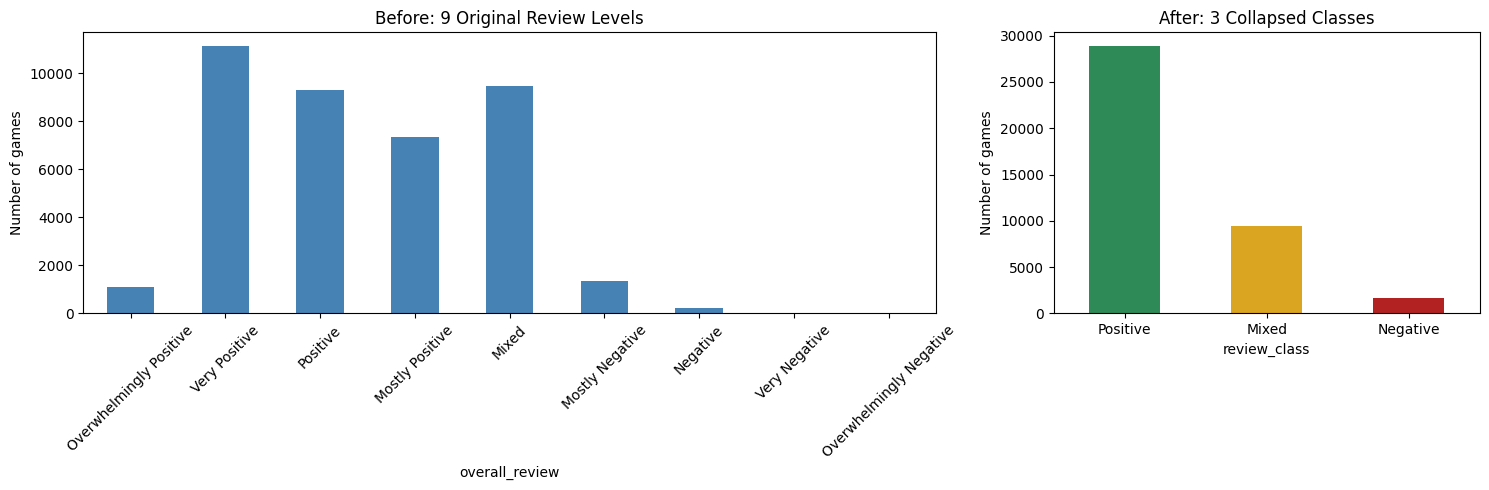

In [16]:
import matplotlib.pyplot as plt

review_map = {
    'Overwhelmingly Positive': 'Positive',
    'Very Positive': 'Positive',
    'Positive': 'Positive',
    'Mostly Positive': 'Positive',
    'Mixed': 'Mixed',
    'Mostly Negative': 'Negative',
    'Negative': 'Negative',
    'Very Negative': 'Negative',
    'Overwhelmingly Negative': 'Negative',
}

df_clean['review_class'] = df_clean['overall_review'].map(review_map)

print(df_clean['review_class'].isna().sum())
print(df_clean['review_class'].value_counts())

order_9 = ['Overwhelmingly Positive', 'Very Positive', 'Positive', 'Mostly Positive',
           'Mixed', 'Mostly Negative', 'Negative', 'Very Negative', 'Overwhelmingly Negative']
order_3 = ['Positive', 'Mixed', 'Negative']

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [2, 1]})

df_clean['overall_review'].value_counts().reindex(order_9).plot(
    kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Before: 9 Original Review Levels')
axes[0].set_ylabel('Number of games')
axes[0].tick_params(axis='x', rotation=45)

df_clean['review_class'].value_counts().reindex(order_3).plot(
    kind='bar', ax=axes[1], color=['seagreen', 'goldenrod', 'firebrick'])
axes[1].set_title('After: 3 Collapsed Classes')
axes[1].set_ylabel('Number of games')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda_target_before_after.png', dpi=200, bbox_inches='tight')
plt.show()

In [17]:
print(df_clean['discounted_price'].isna().sum(), "missing")
print()
print(df_clean['discounted_price'].sample(15, random_state=42).tolist())
print()

pattern = r'^₹[\d,]+(\.\d+)?$'
odd = df_clean['discounted_price'].dropna()
odd = odd[(odd != 'Free') & (~odd.str.match(pattern))]
print(len(odd), "values with unexpected format")
print(odd.value_counts().head(15))

230 missing

['₹349.00', '₹199.00', '₹999.00', '₹450.00', '₹569.00', '₹369.00', 'Free', '₹172.00', '₹299.00', 'Free', '₹299.00', 'Free', '₹529.00', '₹400.00', '₹1,300.00']

0 values with unexpected format
Series([], Name: count, dtype: int64)


count    39790.000000
mean       357.179693
std        450.550836
min          0.000000
25%         70.000000
50%        250.000000
75%        479.000000
max       8325.000000
Name: price_num, dtype: float64

Free games: 6155
Missing: 230

0.500     250.0
0.900     770.0
0.950    1100.0
0.990    2299.0
0.999    4200.0
Name: price_num, dtype: float64


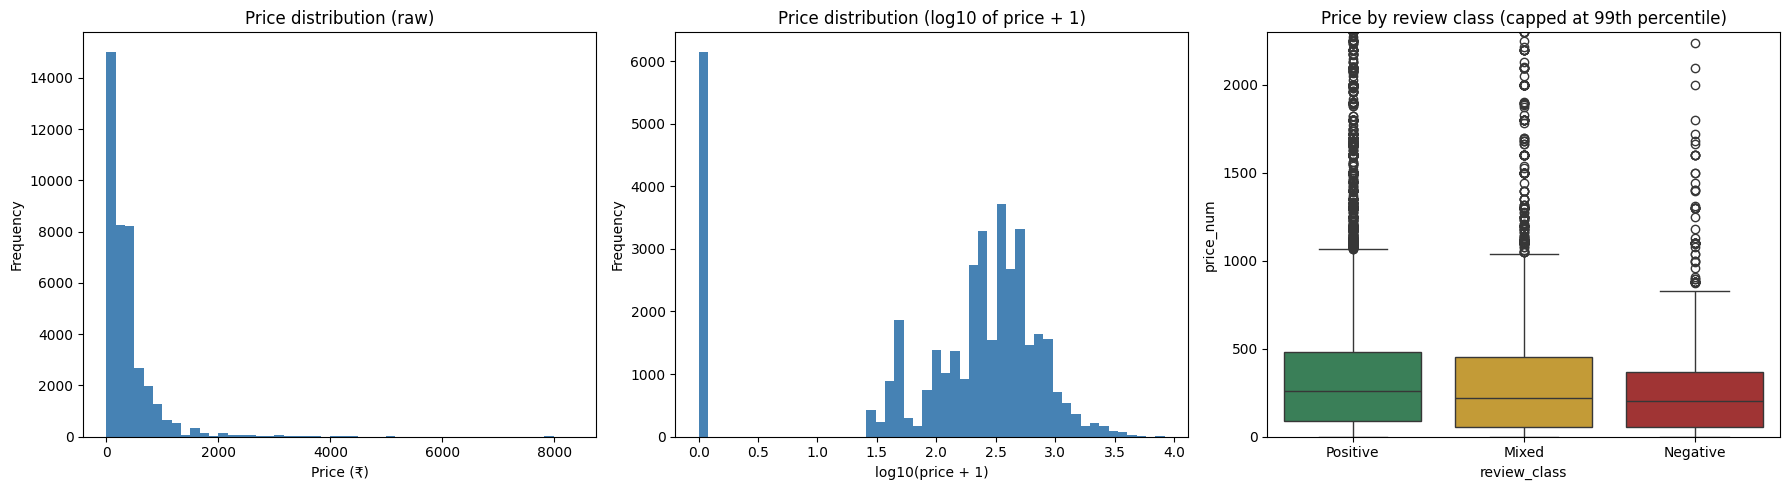

              median   mean  count
review_class                      
Mixed          219.0  320.4   9420
Negative       200.0  292.2   1587
Positive       259.0  372.8  28783


In [18]:
import seaborn as sns

df_clean['price_num'] = (
    df_clean['discounted_price']
    .replace('Free', '0')
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

print(df_clean['price_num'].describe())
print()
print("Free games:", (df_clean['price_num'] == 0).sum())
print("Missing:", df_clean['price_num'].isna().sum())
print()
print(df_clean['price_num'].quantile([0.5, 0.9, 0.95, 0.99, 0.999]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df_clean['price_num'].plot(kind='hist', bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Price distribution (raw)')
axes[0].set_xlabel('Price (₹)')

np_log = (df_clean['price_num'] + 1).apply(lambda x: __import__('math').log10(x))
np_log.plot(kind='hist', bins=50, ax=axes[1], color='steelblue')
axes[1].set_title('Price distribution (log10 of price + 1)')
axes[1].set_xlabel('log10(price + 1)')

order_3 = ['Positive', 'Mixed', 'Negative']
sns.boxplot(data=df_clean, x='review_class', y='price_num', order=order_3, ax=axes[2],
            hue='review_class', hue_order=order_3, legend=False,
            palette=['seagreen', 'goldenrod', 'firebrick'])
axes[2].set_ylim(0, df_clean['price_num'].quantile(0.99))
axes[2].set_title('Price by review class (capped at 99th percentile)')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda_price_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

print(df_clean.groupby('review_class')['price_num'].agg(['median', 'mean', 'count']).round(1))

In [19]:
for col in ['win_support', 'mac_support', 'linux_support']:
    print(col)
    print(pd.crosstab(df_clean['review_class'], df_clean[col], normalize='index').round(3) * 100)
    print()

genre_counts = df_clean['genres'].dropna().str.split(',').explode().str.strip().value_counts()
print("Unique individual genres:", len(genre_counts))
print(genre_counts.head(15))

win_support
win_support   False  True 
review_class              
Mixed           0.0  100.0
Negative        0.1   99.9
Positive        0.0  100.0

mac_support
mac_support   False  True 
review_class              
Mixed          79.6   20.4
Negative       83.6   16.4
Positive       72.2   27.8

linux_support
linux_support  False  True 
review_class               
Mixed           86.7   13.3
Negative        88.8   11.2
Positive        80.7   19.3

Unique individual genres: 22
genres
Indie                    28596
Action                   17303
Adventure                16917
Casual                   15219
Simulation                9274
Strategy                  8534
RPG                       7512
Free to Play              3895
Early Access              3579
Sports                    2064
Racing                    1594
Massively Multiplayer     1158
Education                    7
Utilities                    4
Design & Illustration        4
Name: count, dtype: int64


In [20]:
for col in ['awards', 'dlc_available']:
    print(col)
    print(df_clean.groupby('review_class')[col].agg(
        mean='mean', median='median', max='max',
        share_nonzero=lambda s: (s > 0).mean()).round(3))
    print()

print('age_rating')
print(pd.crosstab(df_clean['review_class'], df_clean['age_rating'], normalize='index').round(3) * 100)
print()

print(df_clean['release_date'].dtype, "| missing:", df_clean['release_date'].isna().sum())
print(df_clean['release_date'].sample(10, random_state=42).tolist())

awards
               mean  median  max  share_nonzero
review_class                                   
Mixed         0.155     0.0   17          0.071
Negative      0.044     0.0    8          0.018
Positive      0.397     0.0   41          0.142

dlc_available
               mean  median  max  share_nonzero
review_class                                   
Mixed         0.574     0.0  200          0.176
Negative      0.357     0.0  167          0.093
Positive      0.841     0.0  200          0.264

age_rating
age_rating       0    1
review_class           
Mixed         94.4  5.6
Negative      95.8  4.2
Positive      94.0  6.0

object | missing: 27
['6 Dec, 2019', '27 Jan, 2022', '23 May, 2017', '26 May, 2023', '16 May, 2019', '3 Aug, 2017', '20 Nov, 2013', '19 Nov, 2019', '26 Nov, 2014', '16 Aug, 2021']


Unparsed after first pass: 85 (27 missing + 58 'Mon YYYY' dates, fixed below)
count    39935.000000
mean      2019.314386
std          3.349247
min       1997.000000
25%       2017.000000
50%       2020.000000
75%       2022.000000
max       2024.000000
Name: release_year, dtype: float64
release_year
2013.0     418
2014.0    1338
2015.0    2005
2016.0    2976
2017.0    3539
2018.0    3770
2019.0    3277
2020.0    4023
2021.0    4605
2022.0    4924
2023.0    5401
2024.0    2366
Name: count, dtype: int64

review_class  Mixed  Negative  Positive
release_year                           
2008.0         15.7       3.5      80.9
2009.0         20.7       4.6      74.7
2010.0         21.8       6.2      72.0
2011.0         27.3       5.2      67.5
2012.0         21.3       4.1      74.6
2013.0         22.5       3.8      73.7
2014.0         30.3       8.1      61.6
2015.0         30.6       7.4      62.0
2016.0         31.0       5.8      63.2
2017.0         31.0       5.8      63.2
2018.0     

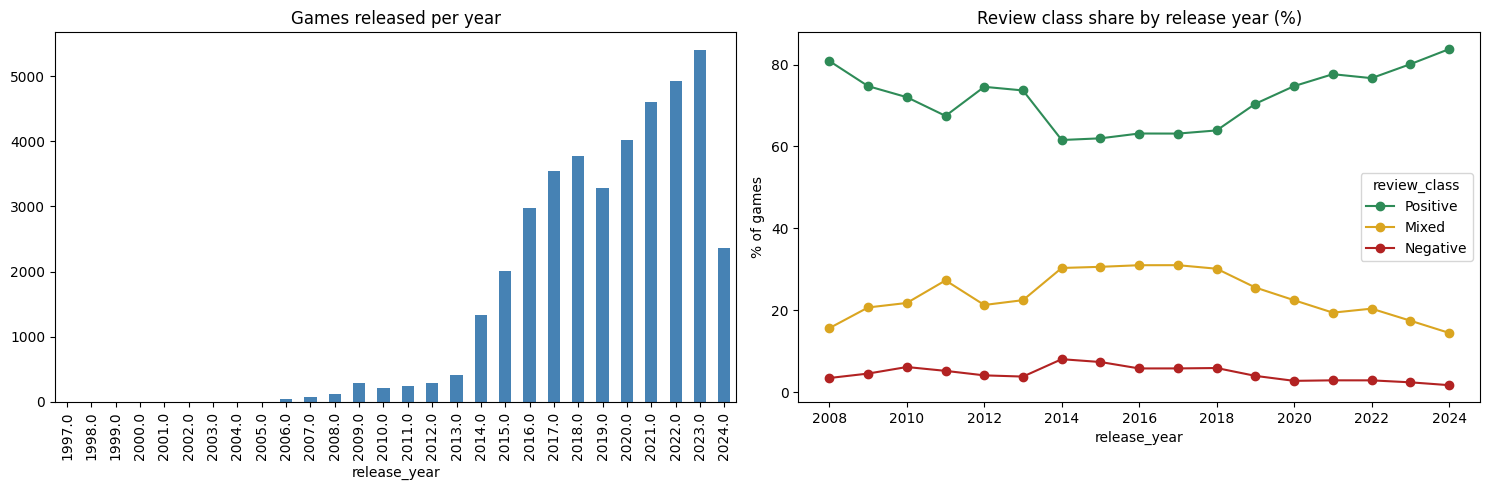

In [21]:
df_clean['release_dt'] = pd.to_datetime(df_clean['release_date'], format='%d %b, %Y', errors='coerce')
df_clean['release_year'] = df_clean['release_dt'].dt.year

print("Unparsed after first pass:", df_clean['release_dt'].isna().sum(), "(27 missing + 58 'Mon YYYY' dates, fixed below)")
print(df_clean['release_year'].describe())
print(df_clean['release_year'].value_counts().sort_index().tail(12))
print()

ct = pd.crosstab(df_clean['release_year'], df_clean['review_class'])
ct = ct[ct.sum(axis=1) >= 100]
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
print(ct_pct.round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df_clean['release_year'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Games released per year')
ct_pct[['Positive', 'Mixed', 'Negative']].plot(
    ax=axes[1], color=['seagreen', 'goldenrod', 'firebrick'], marker='o')
axes[1].set_title('Review class share by release year (%)')
axes[1].set_ylabel('% of games')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda_release_year.png', dpi=200, bbox_inches='tight')
plt.show()

In [22]:
failed = df_clean[df_clean['release_dt'].isna() & df_clean['release_date'].notna()]
print(len(failed), "dates failed to parse (expected 58)")
print(failed['release_date'].value_counts().head(20))

58 dates failed to parse (expected 58)
release_date
Oct 2010    3
Apr 2022    2
Mar 2021    2
Jan 2019    2
Jul 2010    2
Jun 2009    2
May 2014    2
Dec 2015    2
Feb 2020    2
Jul 2018    2
Nov 2014    1
Jan 2021    1
Dec 2016    1
Nov 2020    1
Apr 2019    1
Mar 2019    1
Dec 2012    1
Aug 2017    1
Apr 2020    1
Aug 2015    1
Name: count, dtype: int64


In [23]:
second = pd.to_datetime(df_clean['release_date'], format='%b %Y', errors='coerce')
df_clean['release_dt'] = df_clean['release_dt'].fillna(second)
df_clean['release_year'] = df_clean['release_dt'].dt.year

print("Still unparsed:", df_clean['release_dt'].isna().sum(), "(expected 27)")
print(df_clean['release_year'].describe())

Still unparsed: 27 (expected 27)
count    39993.000000
mean      2019.310379
std          3.351933
min       1997.000000
25%       2017.000000
50%       2020.000000
75%       2022.000000
max       2024.000000
Name: release_year, dtype: float64


               price_num  dlc_available  awards  release_year  age_rating  \
price_num           1.00           0.20    0.21          0.02        0.20   
dlc_available       0.20           1.00    0.23         -0.03        0.16   
awards              0.21           0.23    1.00          0.01        0.11   
release_year        0.02          -0.03    0.01          1.00       -0.09   
age_rating          0.20           0.16    0.11         -0.09        1.00   
win_support        -0.00           0.00   -0.01          0.01       -0.01   
mac_support         0.04           0.11    0.12         -0.18       -0.01   
linux_support       0.03           0.10    0.08         -0.14       -0.01   

               win_support  mac_support  linux_support  
price_num            -0.00         0.04           0.03  
dlc_available         0.00         0.11           0.10  
awards               -0.01         0.12           0.08  
release_year          0.01        -0.18          -0.14  
age_rating           

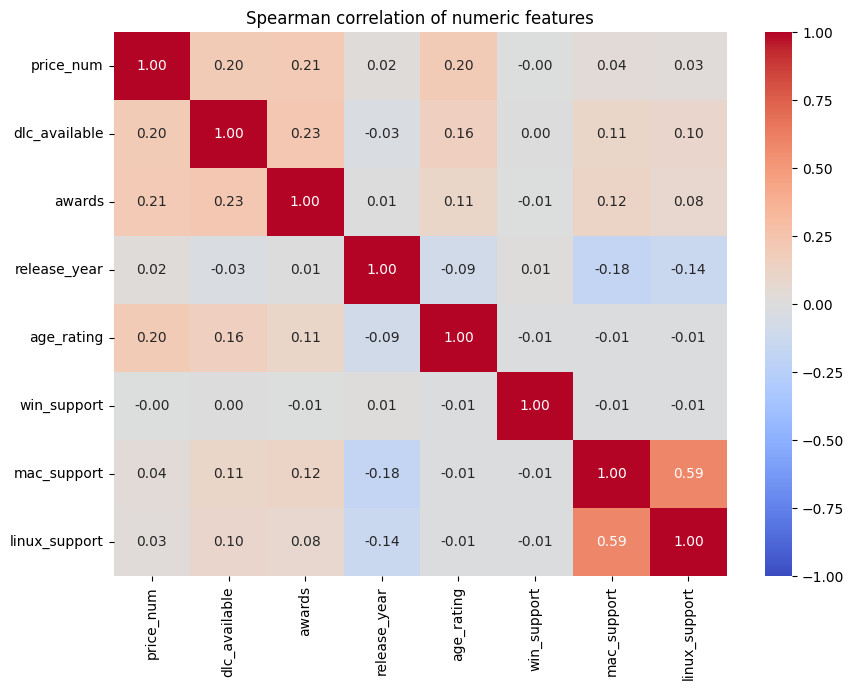

In [24]:
numeric_cols = ['price_num', 'dlc_available', 'awards', 'release_year',
                'age_rating', 'win_support', 'mac_support', 'linux_support']

corr_df = df_clean[numeric_cols].astype(float)
corr = corr_df.corr(method='spearman')
print(corr.round(2))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Spearman correlation of numeric features')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda_correlation_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

price_num: IQR upper fence = 1092.5, rows above fence = 2122 (5.3%), 99th pct = 2299.0, max = 8325
dlc_available: IQR upper fence = 0.0, rows above fence = 9442 (23.6%), 99th pct = 12.0, max = 200
awards: IQR upper fence = 0.0, rows above fence = 4807 (12.0%), 99th pct = 6.0, max = 41

Top 10 DLC counts: [200, 200, 200, 200, 200, 200, 200, 200, 167, 167]
Top 10 award counts: [41, 30, 28, 28, 25, 21, 20, 20, 19, 19]


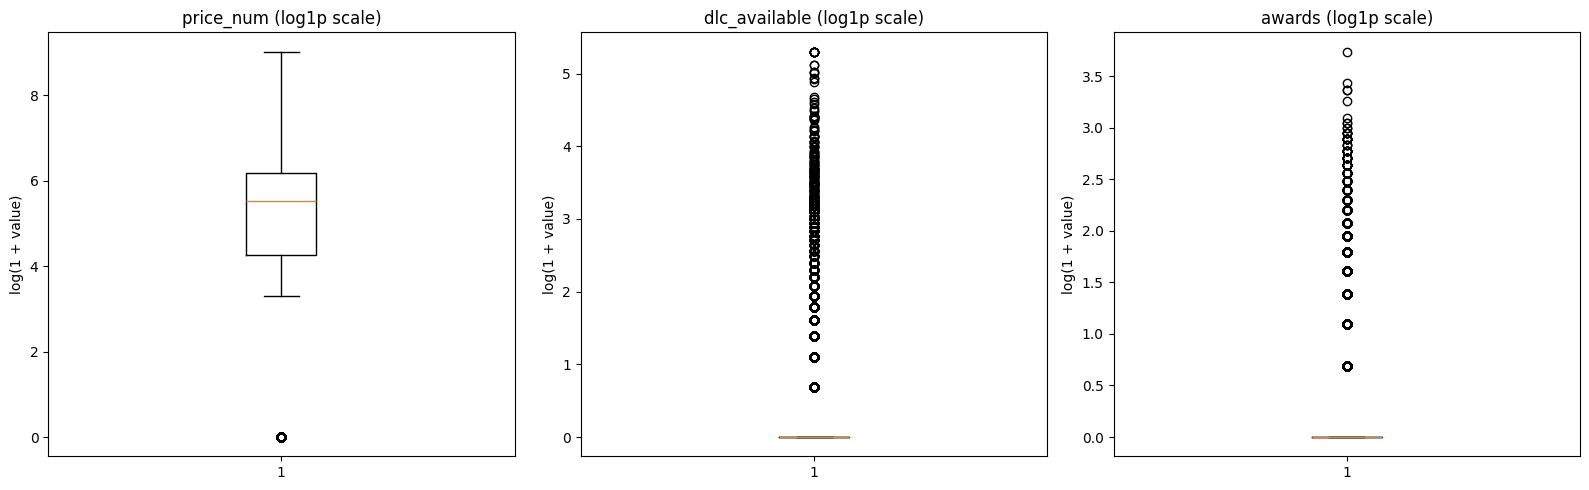

In [25]:
cols = ['price_num', 'dlc_available', 'awards']

for c in cols:
    s = df_clean[c].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    print(f"{c}: IQR upper fence = {upper:.1f}, "
          f"rows above fence = {(s > upper).sum()} ({(s > upper).mean()*100:.1f}%), "
          f"99th pct = {s.quantile(0.99):.1f}, max = {s.max():.0f}")

print()
print("Top 10 DLC counts:", sorted(df_clean['dlc_available'].tolist(), reverse=True)[:10])
print("Top 10 award counts:", sorted(df_clean['awards'].tolist(), reverse=True)[:10])

import numpy as np
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, c in zip(axes, cols):
    ax.boxplot(np.log1p(df_clean[c].dropna()), vert=True)
    ax.set_title(f'{c} (log1p scale)')
    ax.set_ylabel('log(1 + value)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda_outlier_boxplots.png', dpi=200, bbox_inches='tight')
plt.show()

### Extra EDA charts: DLC and awards distributions, genres, awards/DLC by review class

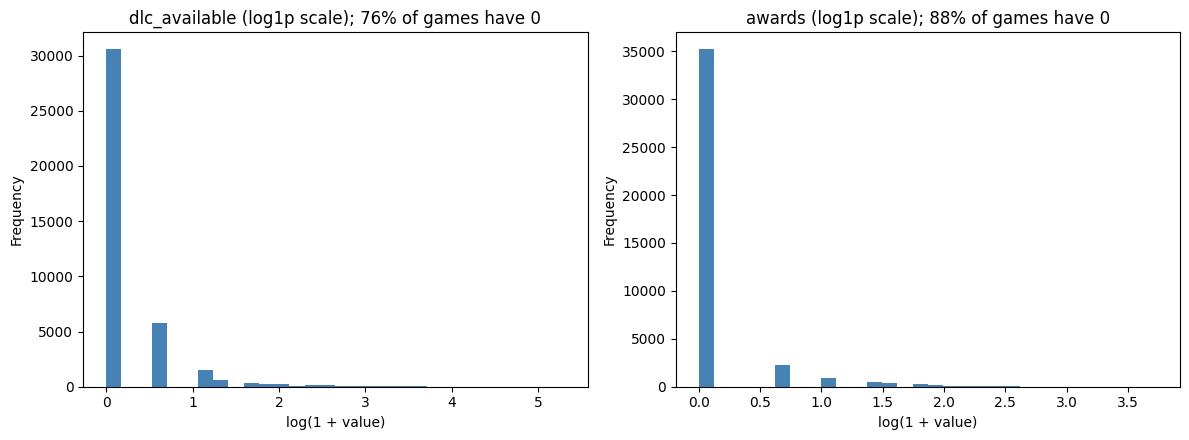

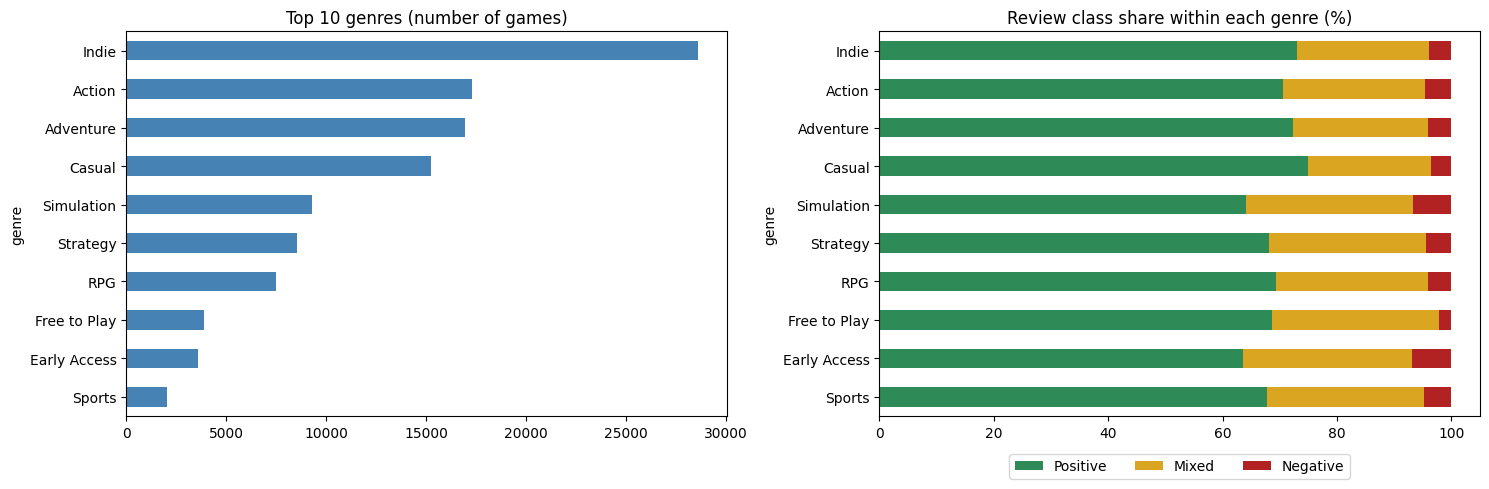

              awards  dlc_available
review_class                       
Positive        14.2           26.4
Mixed            7.1           17.6
Negative         1.8            9.3


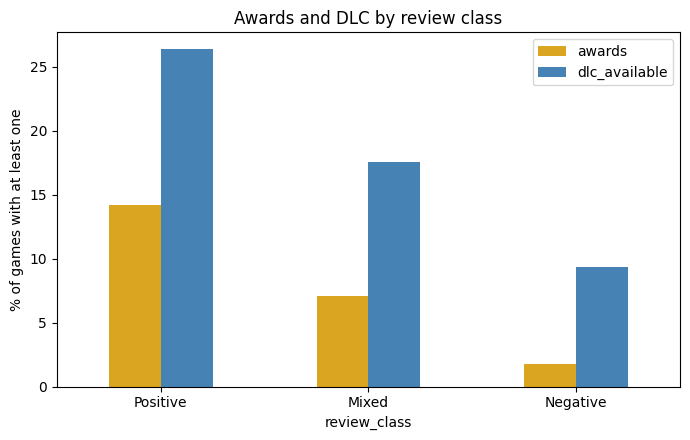

In [26]:
d = df_clean

fig_dir = FIG_DIR
class_order = ['Positive', 'Mixed', 'Negative']; class_colors = ['seagreen', 'goldenrod', 'firebrick']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, c in zip(axes, ['dlc_available', 'awards']):
    np.log1p(d[c].dropna()).plot(kind='hist', bins=30, ax=ax, color='steelblue')
    ax.set_title(f'{c} (log1p scale); {(d[c] == 0).mean()*100:.0f}% of games have 0')
    ax.set_xlabel('log(1 + value)')
plt.tight_layout(); plt.savefig(f'{fig_dir}/eda_dlc_awards_hist.png', dpi=200); plt.show()

g = d[['genres', 'review_class']].dropna().copy()
g['genre'] = g['genres'].str.split(',')
g = g.explode('genre'); g['genre'] = g['genre'].str.strip()
top = g['genre'].value_counts().head(10)
mix = pd.crosstab(g['genre'], g['review_class'], normalize='index').loc[top.index, class_order] * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top[::-1].plot(kind='barh', ax=axes[0], color='steelblue'); axes[0].set_title('Top 10 genres (number of games)')
mix[::-1].plot(kind='barh', stacked=True, ax=axes[1], color=class_colors); axes[1].set_title('Review class share within each genre (%)')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3)
plt.tight_layout(); plt.savefig(f'{fig_dir}/eda_genres.png', dpi=200, bbox_inches='tight'); plt.show()

share = pd.DataFrame({c: d.groupby('review_class')[c].apply(lambda s: (s > 0).mean() * 100).reindex(class_order)
                      for c in ['awards', 'dlc_available']})
print(share.round(1))
share.plot(kind='bar', figsize=(7, 4.5), rot=0, color=['goldenrod', 'steelblue'])
plt.ylabel('% of games with at least one'); plt.title('Awards and DLC by review class')
plt.tight_layout(); plt.savefig(f'{fig_dir}/eda_awards_dlc_by_class.png', dpi=200); plt.show()

In [27]:
cat_counts = df_clean['categories'].dropna().str.split(',').explode().str.strip().value_counts()
print("Unique individual categories:", len(cat_counts))
print(cat_counts.head(15))
print()

for c in ['developer', 'publisher']:
    vc = df_clean[c].value_counts()
    print(f"{c}: {len(vc)} unique | appear once: {(vc == 1).sum()} "
          f"({(vc == 1).sum() / len(vc) * 100:.0f}% of names) | "
          f"games covered by names with 5+ titles: {vc[vc >= 5].sum()} "
          f"({vc[vc >= 5].sum() / len(df_clean) * 100:.0f}%)")
    print(vc.head(8))
    print()

Unique individual categories: 36
categories
Single-player                 38265
Family Sharing                33719
Steam Achievements            23569
Profile Features Limited      14360
Steam Cloud                   13600
Steam Trading Cards            8742
Steam Leaderboards             4321
Online PvP                     4155
Remote Play Together           3653
Online Co-op                   3063
Tracked Controller Support     2263
Stats                          2254
Shared/Split Screen PvP        2136
VR Only                        2002
Shared/Split Screen Co-op      1876
Name: count, dtype: int64

developer: 23897 unique | appear once: 17957 (75% of names) | games covered by names with 5+ titles: 9979 (25%)
developer
Choice of Games               123
Laush Dmitriy Sergeevich      103
Sokpop Collective              87
Square Enix                    80
Dnovel                         74
Hosted Games                   69
Tero Lunkka                    63
KOEI TECMO GAMES CO., LTD.   

### Phase 2 Summary
- **Target:** 9 levels merged into 3 (some levels had only 8 or 30 games). 40,020 games: Positive 72.2%, Mixed 23.7%, Negative 4.1%.
- **Price:** text cleaned to numbers ("Free" = 0). Very skewed (median ₹250, max ₹8,325), so we use log1p. Weak signal.
- **Windows support:** on almost every game (99.9-100%), so it is dropped. Mac and Linux are kept (Mac 27.8% of Positive vs 16.4% of Negative games).
- **Awards and DLC:** more common in Positive games (awards 14.2% vs 1.8% in Negative), but they may be added after release (limitation).
- **Release year:** dates came in two formats, so we parsed twice (only 27 missing). Positive share fell to about 62% in 2014-2018 and rose to 84% by 2024 (era drift).
- **Outliers:** kept, because they are real games; log1p handles the big values.
- **Genres/categories:** 22 genres and 36 category tags, turned into 0/1 columns. **Developer/publisher:** 75% of names appear once, so we use frequency encoding.
- **Limitations:** patterns, not causes; some features may come after launch; review patterns change over time.

## 3. Phase 3: Preprocessing
*Split the data, then turn it into numbers the models can use. Everything is learned from the training data only.*

> The developer/publisher encoding cells change `X_train` in place. If you rerun them, rerun from the train/test split cell first.

In [28]:
data = pd.DataFrame(index=df_clean.index)

data['price_log'] = np.log1p(df_clean['price_num'])
data['is_free'] = (df_clean['price_num'] == 0).astype(int)

data['dlc_log'] = np.log1p(df_clean['dlc_available'])
data['has_dlc'] = (df_clean['dlc_available'] > 0).astype(int)
data['awards_log'] = np.log1p(df_clean['awards'])
data['has_awards'] = (df_clean['awards'] > 0).astype(int)

data['mac_support'] = df_clean['mac_support'].astype(int)
data['linux_support'] = df_clean['linux_support'].astype(int)
data['age_rating'] = df_clean['age_rating'].astype(int)
data['release_year'] = df_clean['release_year']

for col, prefix in [('genres', 'genre'), ('categories', 'cat')]:
    dummies = df_clean[col].fillna('').str.replace(', ', ',').str.get_dummies(sep=',')
    dummies = dummies.loc[:, dummies.sum() >= 50]
    dummies.columns = [f"{prefix}_{c}" for c in dummies.columns]
    data = data.join(dummies)

data['developer'] = df_clean['developer']
data['publisher'] = df_clean['publisher']
data['review_class'] = df_clean['review_class']

print(data.shape)
print([c for c in data.columns if c.startswith('genre_')])
print(len([c for c in data.columns if c.startswith('cat_')]), "category columns")
print(data.isna().sum()[data.isna().sum() > 0])

(40020, 57)
['genre_Action', 'genre_Adventure', 'genre_Casual', 'genre_Early Access', 'genre_Free to Play', 'genre_Indie', 'genre_Massively Multiplayer', 'genre_RPG', 'genre_Racing', 'genre_Simulation', 'genre_Sports', 'genre_Strategy']
32 category columns
price_log       230
release_year     27
developer        59
publisher        80
dtype: int64


In [29]:
from sklearn.model_selection import train_test_split

X = data.drop(columns='review_class')
y = data['review_class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

(28014, 56) (12006, 56)
review_class
Positive    0.722
Mixed       0.237
Negative    0.041
Name: proportion, dtype: float64
review_class
Positive    0.722
Mixed       0.237
Negative    0.041
Name: proportion, dtype: float64


In [30]:
X_train = X_train.copy()
X_test = X_test.copy()

price_median = X_train['price_log'].median()
year_median = X_train['release_year'].median()

for d in (X_train, X_test):
    d['price_log'] = d['price_log'].fillna(price_median)
    d['release_year'] = d['release_year'].fillna(year_median)
    d['developer'] = d['developer'].fillna('Unknown')
    d['publisher'] = d['publisher'].fillna('Unknown')

print(price_median, year_median)
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

5.5254529391317835 2020.0
0 0


In [31]:
import numpy as np

for col in ['developer', 'publisher']:
    counts = X_train[col].value_counts()
    X_train[col + '_freq'] = np.log1p(X_train[col].map(counts))
    X_test[col + '_freq'] = np.log1p(X_test[col].map(counts).fillna(0))

X_train = X_train.drop(columns=['developer', 'publisher'])
X_test = X_test.drop(columns=['developer', 'publisher'])

print(X_train.shape, X_test.shape)
print(X_train[['developer_freq', 'publisher_freq']].describe().round(2))
print('Test rows with unseen developer:', (X_test['developer_freq'] == 0).mean().round(3))
print('Test rows with unseen publisher:', (X_test['publisher_freq'] == 0).mean().round(3))

(28014, 56) (12006, 56)
       developer_freq  publisher_freq
count        28014.00        28014.00
mean             1.23            1.67
std              0.78            1.21
min              0.69            0.69
25%              0.69            0.69
50%              0.69            1.10
75%              1.39            2.40
max              4.43            4.79
Test rows with unseen developer: 0.501
Test rows with unseen publisher: 0.415


In [32]:
for col in ['developer_freq', 'publisher_freq']:
    X_train[col] = np.log1p(np.expm1(X_train[col]).round() - 1)

print(X_train[['developer_freq', 'publisher_freq']].describe().round(2))

       developer_freq  publisher_freq
count        28014.00        28014.00
mean             0.76            1.28
std              1.00            1.46
min              0.00            0.00
25%              0.00            0.00
50%              0.00            0.69
75%              1.10            2.30
max              4.42            4.78


In [33]:
print(pd.crosstab(X_train['is_free'], X_train['genre_Free to Play'], margins=True))
print('Correlation:', X_train['is_free'].corr(X_train['genre_Free to Play']).round(3))

genre_Free to Play      0     1    All
is_free                               
0                   23755     9  23764
1                    1558  2692   4250
All                 25313  2701  28014
Correlation: 0.769


In [34]:
from sklearn.preprocessing import StandardScaler

num_cols = ['price_log', 'dlc_log', 'awards_log', 'release_year',
            'developer_freq', 'publisher_freq']

scaler = StandardScaler().fit(X_train[num_cols])

X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

print(X_train_s[num_cols].describe().loc[['mean', 'std']].round(2))
print(X_test_s[num_cols].describe().loc[['mean', 'std']].round(2))

      price_log  dlc_log  awards_log  release_year  developer_freq  \
mean       -0.0      0.0        -0.0          -0.0             0.0   
std         1.0      1.0         1.0           1.0             1.0   

      publisher_freq  
mean             0.0  
std              1.0  
      price_log  dlc_log  awards_log  release_year  developer_freq  \
mean      -0.02     -0.0        -0.0           0.0             0.0   
std        1.01      1.0         1.0           1.0             1.0   

      publisher_freq  
mean           -0.01  
std             0.99  


### Phase 3 Summary
- **Split first:** 70/30 stratified, 28,014 train and 12,006 test, same class mix (72.2 / 23.7 / 4.1) in both.
- **Missing values:** filled with training medians (price about ₹250, year 2020); missing developer/publisher = "Unknown".
- **Encoding:** genres (12) and categories (32) as 0/1 columns; developer/publisher = log of their number of games in training. Leave-one-out: a game does not count itself. Unseen studios get 0 (about 50% of test developers are unseen).
- **is_free vs "Free to Play" tag:** correlation 0.769 but not the same (1,558 free games lack the tag), so both kept.
- **Scaling:** 6 number columns scaled using training data, only for Logistic Regression and SVM. Trees don't need it.
- **Result:** 11 features become 56 columns.
- **Leakage check:** tags were chosen on all rows before the split; choosing them from training rows only gives the same 12 + 32 tags, so results are unaffected.

## 4. Phase 4: Baselines
*Two dummy models that don't learn. Our models must beat their scores.*

In [35]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score

for strat in ['most_frequent', 'stratified']:
    dummy = DummyClassifier(strategy=strat, random_state=42).fit(X_train, y_train)
    pred = dummy.predict(X_test)
    print(strat)
    print('  accuracy :', round(accuracy_score(y_test, pred), 3))
    print('  macro F1 :', round(f1_score(y_test, pred, average='macro', zero_division=0), 3))
    print('  recall (Mixed, Negative, Positive):',
          recall_score(y_test, pred, average=None, labels=['Mixed', 'Negative', 'Positive'],
                       zero_division=0).round(3))

most_frequent
  accuracy : 0.722
  macro F1 : 0.28
  recall (Mixed, Negative, Positive): [0. 0. 1.]
stratified
  accuracy : 0.579
  macro F1 : 0.334
  recall (Mixed, Negative, Positive): [0.231 0.047 0.723]


### Phase 4 Summary
- **Always-Positive model:** 72.2% accuracy but macro F1 only 0.280. It finds 0 Mixed and 0 Negative games.
- **Random-guess model (stratified):** macro F1 0.334; recall Mixed 0.231, Negative 0.047.
- So accuracy is misleading here. We judge models by macro F1 and per-class recall.
- **Target to beat:** macro F1 above 0.334.

## 5. Phase 5: Model Building and Tuning
*Train 5 models and find their best settings with 5-fold cross-validation on the training data. The test set is not used here.*

### 5a. Setup and stored best settings

In [36]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
cv_pred = cross_val_predict(lr, X_train_s, y_train, cv=skf)

print(classification_report(y_train, cv_pred, digits=3))
print('CV macro F1:', round(f1_score(y_train, cv_pred, average='macro'), 3))

              precision    recall  f1-score   support

       Mixed      0.324     0.267     0.293      6642
    Negative      0.091     0.634     0.159      1138
    Positive      0.835     0.602     0.700     20234

    accuracy                          0.524     28014
   macro avg      0.417     0.501     0.384     28014
weighted avg      0.684     0.524     0.581     28014

CV macro F1: 0.384


In [37]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
sw = compute_sample_weight('balanced', y_train_enc)

results = {
    'Logistic Regression': ({'C': 0.1}, 0.384),
    'Decision Tree': ({'max_depth': None, 'min_samples_leaf': 1}, 0.407),
    'Random Forest': ({'max_features': 0.3, 'min_samples_leaf': 5}, 0.468),
    'SVM': ({'C': 10}, 0.430),
    'XGBoost': ({'learning_rate': 0.1, 'max_depth': 8}, 0.470),
}
for name, (params, cv_f1) in results.items():
    print(f'{name:20} {params}  CV macro F1 {cv_f1}')

Logistic Regression  {'C': 0.1}  CV macro F1 0.384
Decision Tree        {'max_depth': None, 'min_samples_leaf': 1}  CV macro F1 0.407
Random Forest        {'max_features': 0.3, 'min_samples_leaf': 5}  CV macro F1 0.468
SVM                  {'C': 10}  CV macro F1 0.43
XGBoost              {'learning_rate': 0.1, 'max_depth': 8}  CV macro F1 0.47


### 5b. Grid searches (OPTIONAL, over 1 hour): do not rerun
The stored settings above are the result of these cells. Skip to 5c unless you really need to reproduce the tuning. Each search that hit the edge of its grid was followed by a wider one.

In [ ]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42),
    param_grid={'C': [0.01, 0.1, 1, 10]},
    scoring='f1_macro', cv=skf, n_jobs=-1
)
grid.fit(X_train_s, y_train)

print('Best C:', grid.best_params_['C'])
print('Best CV macro F1:', round(grid.best_score_, 3))
print(grid.cv_results_['mean_test_score'].round(3))


Best C: 0.1
Best CV macro F1: 0.384
[0.383 0.384 0.384 0.384]


In [ ]:
from sklearn.tree import DecisionTreeClassifier

results = {'Logistic Regression': (grid.best_params_, round(grid.best_score_, 3))}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid={'max_depth': [3, 5, 8, 12], 'min_samples_leaf': [10, 50, 100]},
    scoring='f1_macro', cv=skf, n_jobs=-1
)
grid_dt.fit(X_train, y_train)

results['Decision Tree'] = (grid_dt.best_params_, round(grid_dt.best_score_, 3))
print('Best params:', grid_dt.best_params_)
print('Best CV macro F1:', round(grid_dt.best_score_, 3))
print(results)

Best params: {'max_depth': 12, 'min_samples_leaf': 10}
Best CV macro F1: 0.365
{'Logistic Regression': ({'C': 0.1}, np.float64(0.384)), 'Decision Tree': ({'max_depth': 12, 'min_samples_leaf': 10}, np.float64(0.365))}


In [ ]:
grid_dt = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid={'max_depth': [12, 16, 20, None], 'min_samples_leaf': [1, 3, 5, 10]},
    scoring='f1_macro', cv=skf, n_jobs=-1
)
grid_dt.fit(X_train, y_train)

results['Decision Tree'] = (grid_dt.best_params_, float(round(grid_dt.best_score_, 3)))
print('Best params:', grid_dt.best_params_)
print('Best CV macro F1:', round(grid_dt.best_score_, 3))
print(results)

Best params: {'max_depth': None, 'min_samples_leaf': 1}
Best CV macro F1: 0.407
{'Logistic Regression': ({'C': 0.1}, np.float64(0.384)), 'Decision Tree': ({'max_depth': None, 'min_samples_leaf': 1}, 0.407)}


In [ ]:
from sklearn.ensemble import RandomForestClassifier

grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample',
                           random_state=42, n_jobs=-1),
    param_grid={'min_samples_leaf': [1, 3, 5], 'max_features': ['sqrt', 0.3]},
    scoring='f1_macro', cv=skf
)
grid_rf.fit(X_train, y_train)

results['Random Forest'] = (grid_rf.best_params_, float(round(grid_rf.best_score_, 3)))
print('Best params:', grid_rf.best_params_)
print('Best CV macro F1:', round(grid_rf.best_score_, 3))
print(grid_rf.cv_results_['mean_test_score'].round(3))

Best params: {'max_features': 0.3, 'min_samples_leaf': 5}
Best CV macro F1: 0.468
[0.389 0.466 0.46  0.395 0.458 0.468]


In [ ]:
grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample',
                           random_state=42, n_jobs=-1),
    param_grid={'min_samples_leaf': [3, 5, 8, 12], 'max_features': [0.3, 0.5]},
    scoring='f1_macro', cv=skf
)
grid_rf.fit(X_train, y_train)

results['Random Forest'] = (grid_rf.best_params_, float(round(grid_rf.best_score_, 3)))
print('Best params:', grid_rf.best_params_)
print('Best CV macro F1:', round(grid_rf.best_score_, 3))
print(grid_rf.cv_results_['mean_test_score'].round(3))

Best params: {'max_features': 0.3, 'min_samples_leaf': 5}
Best CV macro F1: 0.468
[0.458 0.468 0.465 0.455 0.456 0.465 0.465 0.459]


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

grid_svm = GridSearchCV(
    SVC(kernel='rbf', class_weight='balanced', random_state=42),
    param_grid={'C': [0.3, 1, 3]},
    scoring='f1_macro', cv=skf, n_jobs=-1
)
grid_svm.fit(X_train_s, y_train)

results['SVM'] = (grid_svm.best_params_, float(round(grid_svm.best_score_, 3)))
print('Best params:', grid_svm.best_params_)
print('Best CV macro F1:', round(grid_svm.best_score_, 3))
print(grid_svm.cv_results_['mean_test_score'].round(3))

Best params: {'C': 3}
Best CV macro F1: 0.424
[0.413 0.42  0.424]


In [ ]:
grid_svm10 = GridSearchCV(
    SVC(kernel='rbf', class_weight='balanced', random_state=42),
    param_grid={'C': [10]},
    scoring='f1_macro', cv=skf, n_jobs=-1
)
grid_svm10.fit(X_train_s, y_train)

score10 = round(grid_svm10.best_score_, 3)
print('C=10 CV macro F1:', score10)

if score10 > results['SVM'][1]:
    results['SVM'] = ({'C': 10}, float(score10))
print(results['SVM'])

C=10 CV macro F1: 0.43
({'C': 10}, 0.43)


In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
print('Class order:', le.classes_)
sw = compute_sample_weight('balanced', y_train_enc)

grid_xgb = GridSearchCV(
    XGBClassifier(n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                  tree_method='hist', objective='multi:softprob',
                  random_state=42, n_jobs=1),
    param_grid={'max_depth': [4, 6, 8], 'learning_rate': [0.05, 0.1]},
    scoring='f1_macro', cv=skf, n_jobs=-1
)
grid_xgb.fit(X_train, y_train_enc, sample_weight=sw)

results['XGBoost'] = (grid_xgb.best_params_, float(round(grid_xgb.best_score_, 3)))
print('Best params:', grid_xgb.best_params_)
print('Best CV macro F1:', round(grid_xgb.best_score_, 3))
print(grid_xgb.cv_results_['mean_test_score'].round(3))

Class order: ['Mixed' 'Negative' 'Positive']
Best params: {'learning_rate': 0.1, 'max_depth': 8}
Best CV macro F1: 0.47
[0.423 0.444 0.463 0.434 0.454 0.47 ]


In [ ]:
grid_xgb2 = GridSearchCV(
    XGBClassifier(n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                  tree_method='hist', objective='multi:softprob',
                  random_state=42, n_jobs=1),
    param_grid={'max_depth': [10, 12], 'learning_rate': [0.1, 0.2]},
    scoring='f1_macro', cv=skf, n_jobs=-1
)
grid_xgb2.fit(X_train, y_train_enc, sample_weight=sw)

best2 = round(grid_xgb2.best_score_, 3)
print('Best params:', grid_xgb2.best_params_)
print('Best CV macro F1:', best2)
print(grid_xgb2.cv_results_['mean_test_score'].round(3))

if best2 > results['XGBoost'][1]:
    results['XGBoost'] = (grid_xgb2.best_params_, float(best2))
print(results['XGBoost'])

Best params: {'learning_rate': 0.1, 'max_depth': 10}
Best CV macro F1: 0.464
[0.464 0.455 0.456 0.453]
({'learning_rate': 0.1, 'max_depth': 8}, 0.47)


### 5c. Robustness checks

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score

cols = [c for c in X_train.columns if c not in ('developer_freq', 'publisher_freq')]
dt = DecisionTreeClassifier(class_weight='balanced', random_state=42)
pred = cross_val_predict(dt, X_train[cols], y_train, cv=skf)
print('CV macro F1 without developer/publisher:', round(f1_score(y_train, pred, average='macro'), 3))

CV macro F1 without developer/publisher: 0.401


In [ ]:
Xd = X_train[cols].copy()
Xd['y'] = y_train.values

g = Xd.groupby(cols, dropna=False)['y'].agg(['size', 'nunique'])
multi = g[g['size'] > 1]

print('Total unique feature patterns:', len(g))
print('Rows sharing a pattern with another row:', int(multi['size'].sum()),
      round(multi['size'].sum() / len(Xd), 3))
print('Share of those groups with one single label:', round((multi['nunique'] == 1).mean(), 3))

Total unique feature patterns: 25805
Rows sharing a pattern with another row: 3440 0.123
Share of those groups with one single label: 0.569


### Phase 5 Summary
- 5 models tuned with GridSearchCV (5-fold stratified cross-validation, macro F1, training data only).
- Imbalance handled with class weights (sample weights for XGBoost). Scaled data for Logistic Regression and SVM; raw data for tree models.

| Model | Best settings | CV macro F1 |
|---|---|---|
| XGBoost | learning_rate 0.1, max_depth 8 | 0.470 |
| Random Forest | max_features 0.3, min_samples_leaf 5 | 0.468 |
| SVM (RBF) | C = 10 | 0.430 |
| Decision Tree | fully grown (max_depth None, min_samples_leaf 1) | 0.407 |
| Logistic Regression | C = 0.1 | 0.384 |

- **Tuning helped Random Forest most:** 0.389 with default settings to 0.468.
- **Logistic Regression did not improve** (about 0.384 for every C): a straight-line model is too simple here.
- All models beat the best baseline (0.334).
- **Checks:** removing developer/publisher barely changes the score (0.407 to 0.401); duplicate rows do not explain the Decision Tree's score.
- XGBoost and Random Forest differ by only 0.002, so the final choice is made on the test set.

## 6. Phase 6: Evaluation and Comparison
*Score each tuned model once on the test set and compare them.*

The next cell refits the five tuned models on the training set (a few minutes; the SVM is the slowest).

In [38]:
import pandas as pd
from sklearn.preprocessing import label_binarize
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

classes = ['Mixed', 'Negative', 'Positive']
y_test_bin = label_binarize(y_test, classes=classes)

models = {
    'Logistic Regression': (LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000, random_state=42), 'scaled'),
    'Decision Tree': (DecisionTreeClassifier(class_weight='balanced', random_state=42), 'raw'),
    'Random Forest': (RandomForestClassifier(n_estimators=200, max_features=0.3, min_samples_leaf=5,
                                             class_weight='balanced_subsample', random_state=42, n_jobs=-1), 'raw'),
    'SVM': (SVC(kernel='rbf', C=10, class_weight='balanced', random_state=42), 'scaled'),
    'XGBoost': (XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1, subsample=0.8,
                              colsample_bytree=0.8, tree_method='hist', objective='multi:softprob',
                              random_state=42, n_jobs=-1), 'raw'),
}

rows, preds = [], {}
for name, (model, kind) in models.items():
    Xtr, Xte = (X_train_s, X_test_s) if kind == 'scaled' else (X_train, X_test)
    if name == 'XGBoost':
        model.fit(Xtr, y_train_enc, sample_weight=sw)
        pred = le.inverse_transform(model.predict(Xte))
    else:
        model.fit(Xtr, y_train)
        pred = model.predict(Xte)
    scores = model.decision_function(Xte) if name == 'SVM' else model.predict_proba(Xte)
    auc = np.mean([roc_auc_score(y_test_bin[:, k], scores[:, k]) for k in range(3)])
    rec = recall_score(y_test, pred, average=None, labels=classes)
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Macro precision': precision_score(y_test, pred, average='macro'),
                 'Macro recall': recall_score(y_test, pred, average='macro'),
                 'Macro F1': f1_score(y_test, pred, average='macro'),
                 'Recall Mixed': rec[0], 'Recall Negative': rec[1], 'Recall Positive': rec[2],
                 'ROC-AUC (OvR)': auc})
    preds[name] = pred
    print('done:', name)

test_table = pd.DataFrame(rows).set_index('Model').round(3)
print(test_table)

done: Logistic Regression
done: Decision Tree
done: Random Forest
done: SVM
done: XGBoost
                     Accuracy  Macro precision  Macro recall  Macro F1  \
Model                                                                    
Logistic Regression     0.525            0.421         0.501     0.387   
Decision Tree           0.621            0.392         0.397     0.394   
Random Forest           0.668            0.462         0.483     0.470   
SVM                     0.583            0.435         0.501     0.433   
XGBoost                 0.654            0.453         0.485     0.462   

                     Recall Mixed  Recall Negative  Recall Positive  \
Model                                                                 
Logistic Regression         0.281            0.623            0.600   
Decision Tree               0.326            0.119            0.746   
Random Forest               0.432            0.248            0.769   
SVM                         0.454   

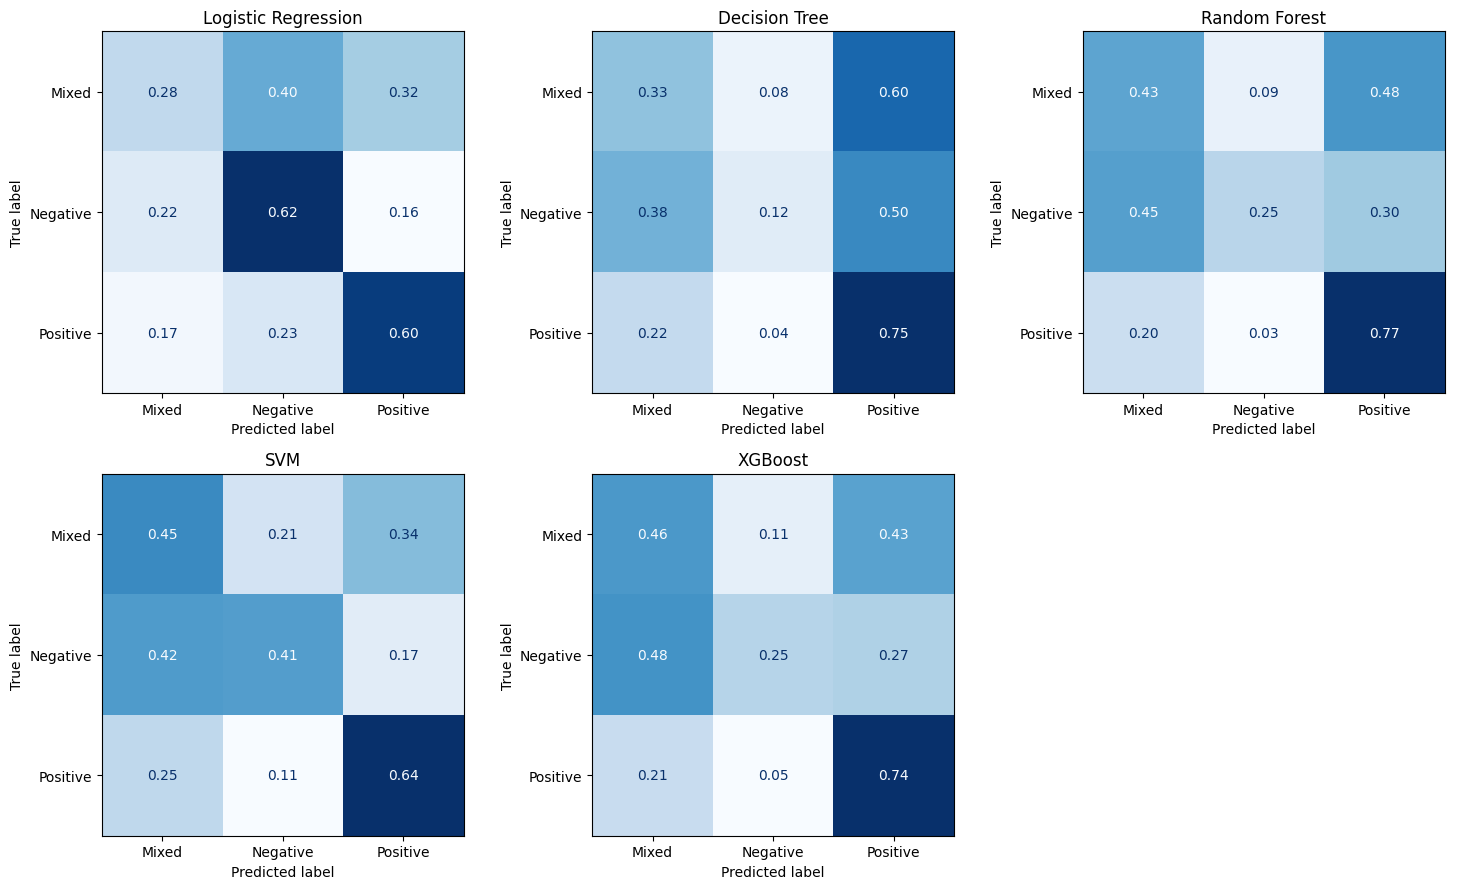

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, pred) in zip(axes.ravel(), preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=classes, normalize='true',
        values_format='.2f', cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(name)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.inspection import permutation_importance

rf = models['Random Forest'][0]

imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print('Impurity importance (top 15):')
print(imp.head(15).round(3))

pi = permutation_importance(rf, X_test, y_test, scoring='f1_macro',
                            n_repeats=5, random_state=42, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
print('\nPermutation importance, drop in macro F1 (top 15):')
print(perm.head(15).round(4))

Impurity importance (top 15):
price_log                       0.156
release_year                    0.130
publisher_freq                  0.096
developer_freq                  0.077
cat_Steam Cloud                 0.036
genre_Adventure                 0.032
genre_Action                    0.030
genre_Casual                    0.030
genre_Simulation                0.030
cat_Steam Achievements          0.029
dlc_log                         0.024
genre_Indie                     0.023
genre_Strategy                  0.023
mac_support                     0.021
cat_Profile Features Limited    0.020
dtype: float64

Permutation importance, drop in macro F1 (top 15):
release_year                    0.0630
cat_Steam Cloud                 0.0160
genre_Simulation                0.0158
cat_Steam Achievements          0.0085
price_log                       0.0076
publisher_freq                  0.0074
developer_freq                  0.0073
genre_Adventure                 0.0069
cat_Steam Trading Car

In [ ]:
from sklearn.model_selection import cross_val_score

rf_cv = RandomForestClassifier(n_estimators=200, max_features=0.3, min_samples_leaf=5,
                               class_weight='balanced_subsample', random_state=42, n_jobs=-1)
cols_no_year = [c for c in X_train.columns if c != 'release_year']

scores = cross_val_score(rf_cv, X_train[cols_no_year], y_train, cv=skf, scoring='f1_macro')
print('CV macro F1 without release_year:', round(scores.mean(), 3))

CV macro F1 without release_year: 0.445


In [ ]:
cv_scores = pd.Series({name: val[1] for name, val in results.items()})

comp = test_table.copy()
comp.insert(0, 'CV macro F1', cv_scores)

baselines = pd.DataFrame({
    'CV macro F1': [np.nan, np.nan],
    'Accuracy': [0.722, 0.579],
    'Macro precision': [np.nan, np.nan],
    'Macro recall': [np.nan, np.nan],
    'Macro F1': [0.280, 0.334],
    'Recall Mixed': [0.0, 0.231],
    'Recall Negative': [0.0, 0.047],
    'Recall Positive': [1.0, 0.723],
    'ROC-AUC (OvR)': [np.nan, np.nan],
}, index=['Baseline: most_frequent', 'Baseline: stratified'])

comp = pd.concat([comp.sort_values('Macro F1', ascending=False), baselines])
print(comp.round(3).to_string())

comp.round(3).to_csv('/content/drive/MyDrive/Colab Notebooks/ML_Project/model_comparison.csv')

                         CV macro F1  Accuracy  Macro precision  Macro recall  Macro F1  Recall Mixed  Recall Negative  Recall Positive  ROC-AUC (OvR)
Random Forest                  0.468     0.668            0.462         0.483     0.470         0.432            0.248            0.769          0.724
XGBoost                        0.470     0.654            0.453         0.485     0.462         0.461            0.254            0.740          0.714
SVM                            0.430     0.583            0.435         0.501     0.433         0.454            0.412            0.636          0.682
Decision Tree                  0.407     0.621            0.392         0.397     0.394         0.326            0.119            0.746          0.556
Logistic Regression            0.384     0.525            0.421         0.501     0.387         0.281            0.623            0.600          0.691
Baseline: most_frequent          NaN     0.722              NaN           NaN     0.280       

### 6b. Extra evaluation: ROC curves, Precision-Recall curves, PR-AUC, specificity, comparison chart, feature importance chart

                     PR-AUC (macro)  PR-AUC Negative  Specificity (macro)  \
Model                                                                       
Logistic Regression           0.428            0.110                0.752   
Decision Tree                 0.356            0.048                0.715   
Random Forest                 0.466            0.150                0.763   
SVM                           0.430            0.118                0.763   
XGBoost                       0.463            0.127                0.768   

                     Specificity Negative  
Model                                      
Logistic Regression                 0.729  
Decision Tree                       0.953  
Random Forest                       0.953  
SVM                                 0.865  
XGBoost                             0.937  

PR-AUC of a random model = class share: {'Mixed': np.float64(0.237), 'Negative': np.float64(0.041), 'Positive': np.float64(0.722)}


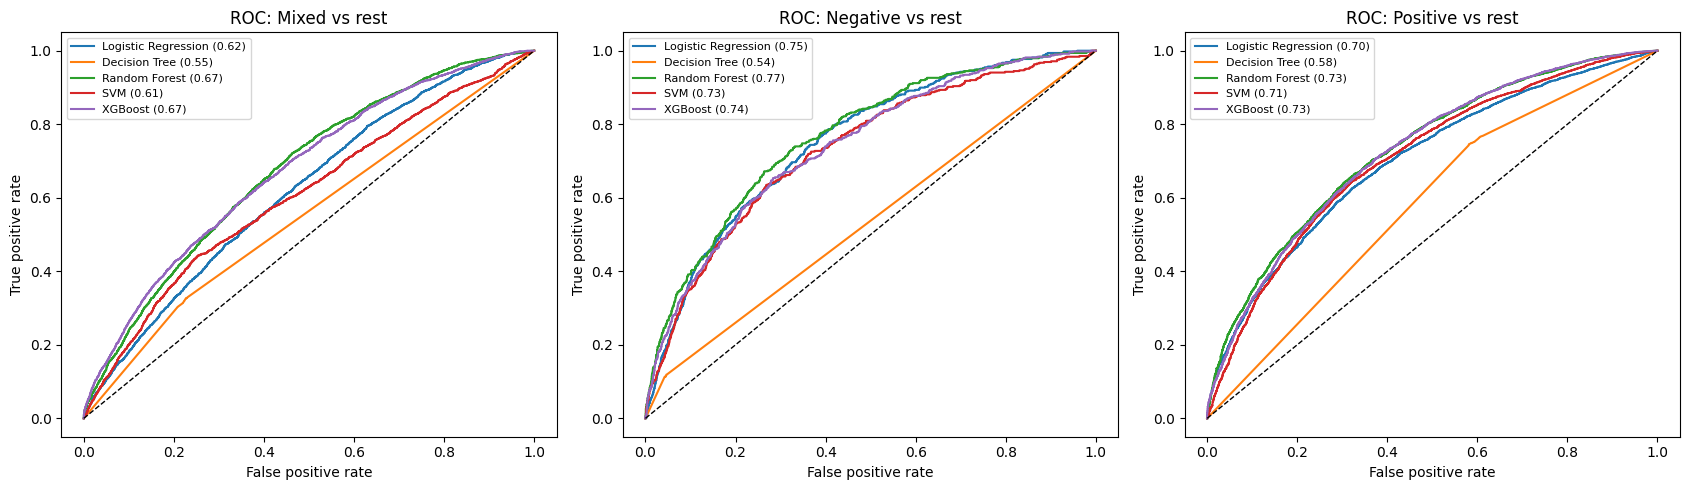

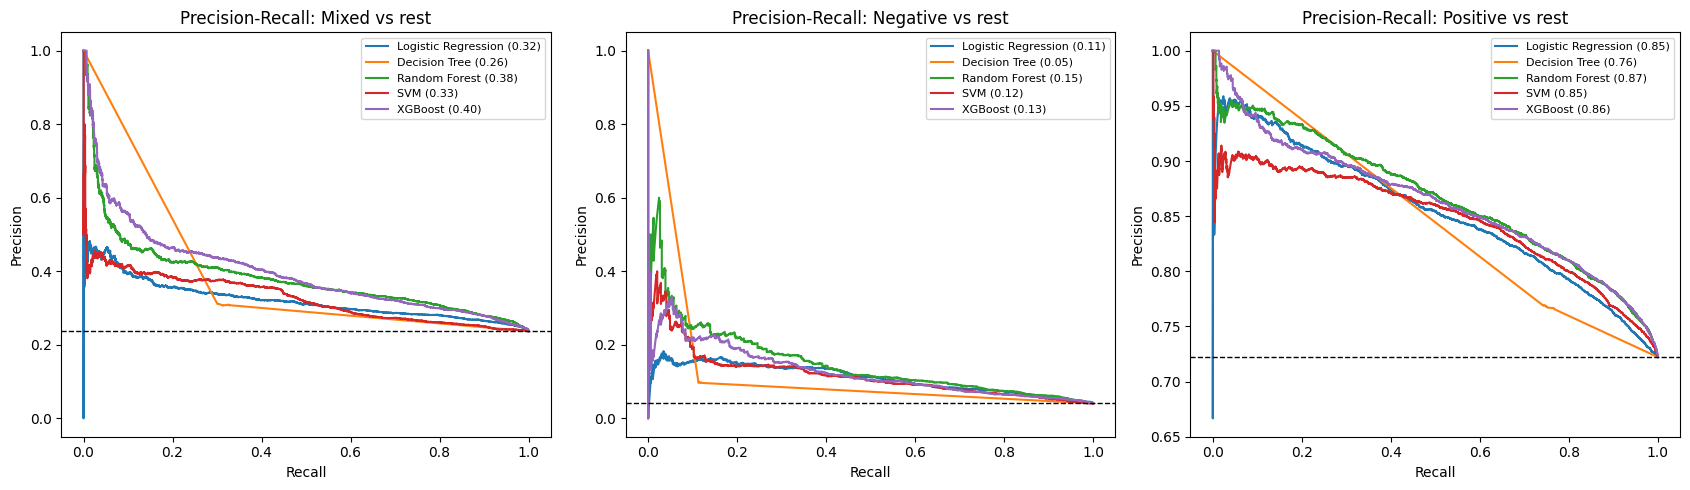

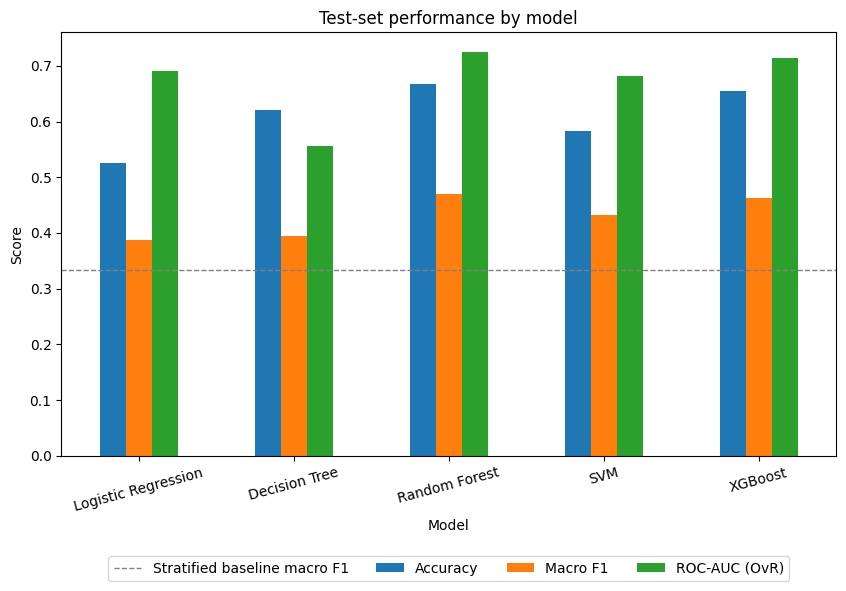

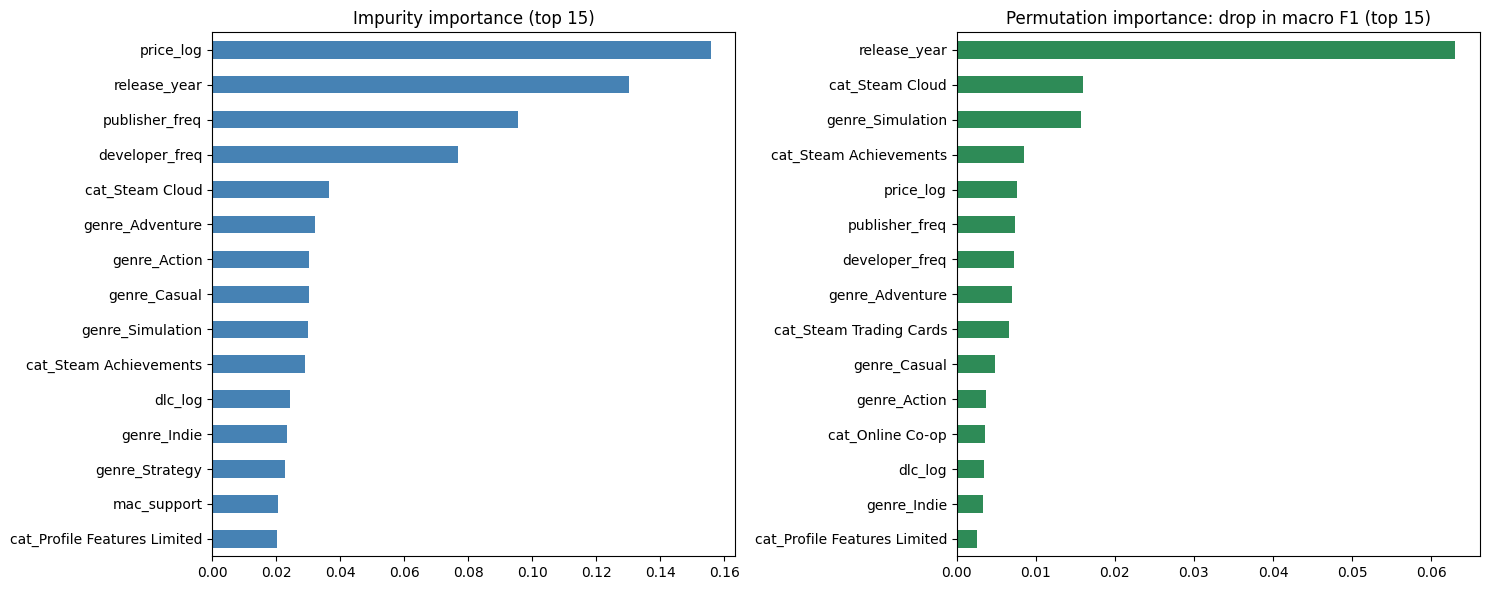

In [ ]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, roc_auc_score, confusion_matrix

fig_dir = FIG_DIR if 'FIG_DIR' in globals() else '/content/drive/MyDrive/Colab Notebooks/ML_Project/figures'
os.makedirs(fig_dir, exist_ok=True)
colors = {'Logistic Regression':'tab:blue','Decision Tree':'tab:orange','Random Forest':'tab:green',
          'SVM':'tab:red','XGBoost':'tab:purple'}

scores = {}
for name, (model, kind) in models.items():
    Xte = X_test_s if kind == 'scaled' else X_test
    scores[name] = model.decision_function(Xte) if name == 'SVM' else model.predict_proba(Xte)

rows = []
for name in models:
    ap = [average_precision_score(y_test_bin[:, k], scores[name][:, k]) for k in range(3)]
    cm = confusion_matrix(y_test, preds[name], labels=classes)
    spec = []
    for k in range(3):
        tn = cm.sum() - cm[k, :].sum() - cm[:, k].sum() + cm[k, k]
        fp = cm[:, k].sum() - cm[k, k]
        spec.append(tn / (tn + fp))
    rows.append({'Model': name, 'PR-AUC (macro)': np.mean(ap), 'PR-AUC Negative': ap[1],
                 'Specificity (macro)': np.mean(spec), 'Specificity Negative': spec[1]})
extra = pd.DataFrame(rows).set_index('Model').round(3)
print(extra)
print('\nPR-AUC of a random model = class share:',
      {c: round((y_test == c).mean(), 3) for c in classes})
extra.to_csv('/content/drive/MyDrive/Colab Notebooks/ML_Project/extra_metrics.csv')

for kind_, fname in [('roc', 'roc_curves.png'), ('pr', 'pr_curves.png')]:
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    for k, ax in enumerate(axes):
        for name in models:
            if kind_ == 'roc':
                x, y, _ = roc_curve(y_test_bin[:, k], scores[name][:, k])
                lab = f"{name} ({roc_auc_score(y_test_bin[:, k], scores[name][:, k]):.2f})"
            else:
                y, x, _ = precision_recall_curve(y_test_bin[:, k], scores[name][:, k])
                lab = f"{name} ({average_precision_score(y_test_bin[:, k], scores[name][:, k]):.2f})"
            ax.plot(x, y, color=colors[name], label=lab)
        if kind_ == 'roc':
            ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
        else:
            ax.axhline(y_test_bin[:, k].mean(), color='k', ls='--', lw=1)
            ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
        ax.set_title(f"{'ROC' if kind_=='roc' else 'Precision-Recall'}: {classes[k]} vs rest")
        ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f'{fig_dir}/{fname}', dpi=200); plt.show()

test_table[['Accuracy', 'Macro F1', 'ROC-AUC (OvR)']].plot(kind='bar', figsize=(10, 5.5), rot=15)
plt.axhline(0.334, color='gray', ls='--', lw=1, label='Stratified baseline macro F1')
plt.title('Test-set performance by model'); plt.ylabel('Score')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=4)
plt.savefig(f'{fig_dir}/model_comparison.png', dpi=200, bbox_inches='tight'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
imp.head(15)[::-1].plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Impurity importance (top 15)')
perm.head(15)[::-1].plot(kind='barh', ax=axes[1], color='seagreen')
axes[1].set_title('Permutation importance: drop in macro F1 (top 15)')
plt.tight_layout(); plt.savefig(f'{fig_dir}/feature_importance.png', dpi=200); plt.show()

### Interpreting the 6b results
- **ROC curves:** all models except the Decision Tree are clearly better than random. Mixed is the hardest class to separate.
- **Precision-Recall curves:** for Negative, Random Forest's PR-AUC is 0.15 vs 0.041 for random (about 3.7x better), but precision stays low.
- **Negative has high ROC-AUC but low PR-AUC:** ROC benefits from the many non-Negative games; PR shows how hard a 4.1% class is to find.
- **Specificity:** Random Forest rarely calls a game Negative by mistake (0.953); Logistic Regression does it more (0.729), which is also why it finds the most Negatives (recall 0.62).
- **Comparison chart:** all models beat the baseline; the Decision Tree's ROC-AUC is low because a fully grown tree gives hard 0/1 scores.
- **Feature importance:** impurity importance puts price first, but it favours features with many values. Permutation importance (more reliable) puts `release_year` far ahead (0.063).

### Phase 6 Summary
- Each model was scored **once** on the 12,006 test games. Test macro F1 is within 0.013 of the CV score, so there is no overfitting.
- **Ranking (macro F1):** Random Forest 0.470, XGBoost 0.462, SVM 0.433, Decision Tree 0.394, Logistic Regression 0.387. Baselines: 0.334 and 0.280.
- **Random Forest is best:** also highest accuracy (0.668) and ROC-AUC (0.724). XGBoost is very close.
- All accuracies are below 72.2% on purpose: class weights trade some Positive accuracy for finding Mixed and Negative games.
- **Mistakes are between neighbouring classes** (Negative predicted as Mixed). Mixed is the hardest class.
- **Most important feature:** `release_year` (score drops 0.063 without it; CV 0.468 to 0.445 when removed).
- **Limitations:** patterns, not causes; some tags and awards may come after launch.

## 7. Save bundle
*Save the trained Random Forest and the data it needs to one file in Drive.*

> **WARNING: run this only right after a full fresh build (Phases 1 to 6 in the same session). Never run it after a disconnect.** It overwrites the saved bundle in Drive and needs the `data` table, which is lost when the session resets.

It also defines `dev_counts` and `pub_counts`, which the live demo needs.

In [ ]:
import joblib, os

SAVE_DIR = '/content/drive/MyDrive/Colab Notebooks/ML_Project/saved'
os.makedirs(SAVE_DIR, exist_ok=True)

train_raw = data.loc[X_train.index]
dev_counts = train_raw['developer'].fillna('Unknown').value_counts()
pub_counts = train_raw['publisher'].fillna('Unknown').value_counts()
rf = models['Random Forest'][0]
bundle = {
    'rf': rf,
    'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test,
    'dev_counts': dev_counts,
    'pub_counts': pub_counts,
}
joblib.dump(bundle, f'{SAVE_DIR}/ml_project_bundle.joblib', compress=3)
print('Saved,', round(os.path.getsize(f'{SAVE_DIR}/ml_project_bundle.joblib') / 1e6), 'MB')

Saved, 28 MB


## 8. Live demo
*Enter a game's details and get the predicted review class.* The scores are class-weighted model scores, not true probabilities.

Needs: `X_train`, `dev_counts`, `pub_counts`, `rf` (from Section 7 or Section 9).

In [47]:
genre_names = [c[6:] for c in X_train.columns if c.startswith('genre_')]
cat_names = [c[4:] for c in X_train.columns if c.startswith('cat_')]
print('Genres:', genre_names)
print('Categories:', cat_names)
print('Age ratings in data:', sorted(X_train['age_rating'].unique()))
print('Max dlc_log:', round(X_train['dlc_log'].max(), 2), '| log1p(200) =', round(np.log1p(200), 2))

def predict_game(price, release_year, age_rating, genres_sel=(), cats_sel=(),
                 mac=0, linux=0, dlc=0, awards=0, developer='', publisher=''):
    row = pd.DataFrame(0.0, index=[0], columns=X_train.columns)
    row['price_log'] = np.log1p(price)
    row['is_free'] = int(price == 0)
    row['dlc_log'] = np.log1p(dlc)
    row['has_dlc'] = int(dlc > 0)
    row['awards_log'] = np.log1p(awards)
    row['has_awards'] = int(awards > 0)
    row['mac_support'] = mac
    row['linux_support'] = linux
    row['age_rating'] = age_rating
    row['release_year'] = release_year
    for g in genres_sel:
        if g not in genre_names: raise ValueError(f'Unknown genre: {g}')
        row['genre_' + g] = 1
    for c in cats_sel:
        if c not in cat_names: raise ValueError(f'Unknown category: {c}')
        row['cat_' + c] = 1
    row['developer_freq'] = np.log1p(dev_counts.get(developer, 0))
    row['publisher_freq'] = np.log1p(pub_counts.get(publisher, 0))
    probs = dict(zip(rf.classes_, rf.predict_proba(row)[0].round(2)))
    return rf.predict(row)[0], probs

print(predict_game(price=499, release_year=2021,
                   age_rating=int(X_train['age_rating'].median()),
                   genres_sel=['Action', 'Indie'], cats_sel=['Steam Cloud'],
                   mac=1, dlc=2))

Genres: ['Action', 'Adventure', 'Casual', 'Early Access', 'Free to Play', 'Indie', 'Massively Multiplayer', 'RPG', 'Racing', 'Simulation', 'Sports', 'Strategy']
Categories: ['Captions available', 'Commentary available', 'Cross-Platform Multiplayer', 'Family Sharing', 'HDR available', 'In-App Purchases', 'Includes level editor', 'LAN Co-op', 'LAN PvP', 'MMO', 'Online Co-op', 'Online PvP', 'Profile Features Limited', 'Remote Play Together', 'Remote Play on Phone', 'Remote Play on TV', 'Remote Play on Tablet', 'Shared/Split Screen Co-op', 'Shared/Split Screen PvP', 'Single-player', 'Stats', 'Steam Achievements', 'Steam Cloud', 'Steam Leaderboards', 'Steam Trading Cards', 'Steam Turn Notifications', 'Steam Workshop', 'Steam is learning about this game', 'Tracked Controller Support', 'VR Only', 'VR Supported', 'Valve Anti-Cheat enabled']
Age ratings in data: [np.int64(0), np.int64(1)]
Max dlc_log: 5.3 | log1p(200) = 5.3
('Positive', {'Mixed': np.float64(0.14), 'Negative': np.float64(0.03), 

In [ ]:
import ipywidgets as w
from IPython.display import display, clear_output

genres = ['Action','Adventure','Casual','Early Access','Free to Play','Indie',
          'Massively Multiplayer','RPG','Racing','Simulation','Sports','Strategy']
cats = ['Captions available','Commentary available','Cross-Platform Multiplayer','Family Sharing',
        'HDR available','In-App Purchases','Includes level editor','LAN Co-op','LAN PvP','MMO',
        'Online Co-op','Online PvP','Remote Play Together','Remote Play on Phone','Remote Play on TV',
        'Remote Play on Tablet','Shared/Split Screen Co-op','Shared/Split Screen PvP','Single-player',
        'Stats','Steam Achievements','Steam Cloud','Steam Leaderboards','Steam Trading Cards',
        'Steam Turn Notifications','Steam Workshop','Tracked Controller Support','VR Only',
        'VR Supported','Valve Anti-Cheat enabled']

price  = w.FloatText(value=9.99, description='Price (₹)')
year   = w.IntSlider(value=2024, min=2000, max=2026, description='Release year')
age    = w.Checkbox(value=False, description='Age-restricted (age_rating = 1)')
mac    = w.Checkbox(value=False, description='Mac support')
linux  = w.Checkbox(value=False, description='Linux support')
dlc    = w.IntText(value=0, description='DLC count')
awards = w.IntText(value=0, description='Awards')
dev    = w.Text(description='Developer')
pub    = w.Text(description='Publisher')

gbox = {g: w.Checkbox(value=False, description=g, indent=False) for g in genres}
cbox = {c: w.Checkbox(value=False, description=c, indent=False) for c in cats}
grid = lambda d: w.GridBox(list(d.values()),
        layout=w.Layout(grid_template_columns='repeat(3, 1fr)'))

btn = w.Button(description='Predict', button_style='success')
out = w.Output()

def on_click(_):
    with out:
        clear_output()
        label, scores = predict_game(
            price.value, year.value, int(age.value),
            genres_sel=tuple(g for g, b in gbox.items() if b.value),
            cats_sel=tuple(c for c, b in cbox.items() if b.value),
            mac=int(mac.value), linux=int(linux.value),
            dlc=dlc.value, awards=awards.value,
            developer=dev.value, publisher=pub.value)
        print(f"Predicted review class: {label}\n")
        for k, v in sorted(scores.items(), key=lambda x: -x[1]):
            print(f"  {k:<9} {v:.2f}")
btn.on_click(on_click)

display(w.VBox([price, year, age, mac, linux, dlc, awards, dev, pub,
                w.HTML('<b>Genres</b>'), grid(gbox),
                w.HTML('<b>Categories</b>'), grid(cbox), btn, out]))

## 9. Restore after disconnect
*If Colab disconnects, bring the model back without retraining.*

Run **only these two cells** (in order), then Section 6b and/or Section 8. Do not "Run all": the grid searches take over an hour.

1. **Cell B:** loads the saved Random Forest, train/test tables and developer/publisher counts from Drive.
2. **Recovery cell:** refits the other four models with the stored settings. Numbers should match Phase 6 (Random Forest macro F1 0.470, XGBoost 0.462, SVM 0.433, Decision Tree 0.394, Logistic Regression 0.387; top feature `release_year`).

If `drive.mount` says "Mountpoint must not already contain files", use Runtime > Disconnect and delete runtime, then run Cell B first.

**Cell B**

In [46]:
from google.colab import drive
drive.mount('/content/drive')

import joblib, numpy as np, pandas as pd
from sklearn.metrics import f1_score

b = joblib.load('/content/drive/MyDrive/Colab Notebooks/ML_Project/saved/ml_project_bundle.joblib')
rf = b['rf']
X_train, X_test, y_train, y_test = b['X_train'], b['X_test'], b['y_train'], b['y_test']
dev_counts, pub_counts = b['dev_counts'], b['pub_counts']
models = {'Random Forest': (rf, 'raw')}

print(X_train.shape, X_test.shape)
print('Test macro F1:', round(f1_score(y_test, rf.predict(X_test), average='macro'), 3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(28014, 56) (12006, 56)
Test macro F1: 0.47


**Recovery cell**

In [ ]:
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.inspection import permutation_importance

classes = ['Mixed', 'Negative', 'Positive']
y_test_bin = label_binarize(y_test, classes=classes)

num_cols = ['price_log', 'dlc_log', 'awards_log', 'release_year', 'developer_freq', 'publisher_freq']
scaler = StandardScaler().fit(X_train[num_cols])
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

le = LabelEncoder(); y_train_enc = le.fit_transform(y_train)
sw = compute_sample_weight('balanced', y_train_enc)

models = {
    'Logistic Regression': (LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000, random_state=42), 'scaled'),
    'Decision Tree': (DecisionTreeClassifier(class_weight='balanced', random_state=42), 'raw'),
    'Random Forest': (RandomForestClassifier(n_estimators=200, max_features=0.3, min_samples_leaf=5,
                                             class_weight='balanced_subsample', random_state=42, n_jobs=-1), 'raw'),
    'SVM': (SVC(kernel='rbf', C=10, class_weight='balanced', random_state=42), 'scaled'),
    'XGBoost': (XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1, subsample=0.8,
                              colsample_bytree=0.8, tree_method='hist', objective='multi:softprob',
                              random_state=42, n_jobs=-1), 'raw'),
}

rows, preds = [], {}
for name, (model, kind) in models.items():
    Xtr, Xte = (X_train_s, X_test_s) if kind == 'scaled' else (X_train, X_test)
    if name == 'XGBoost':
        model.fit(Xtr, y_train_enc, sample_weight=sw)
        pred = le.inverse_transform(model.predict(Xte))
    else:
        model.fit(Xtr, y_train)
        pred = model.predict(Xte)
    sc = model.decision_function(Xte) if name == 'SVM' else model.predict_proba(Xte)
    auc = np.mean([roc_auc_score(y_test_bin[:, k], sc[:, k]) for k in range(3)])
    rec = recall_score(y_test, pred, average=None, labels=classes)
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred),
                 'Macro precision': precision_score(y_test, pred, average='macro'),
                 'Macro recall': recall_score(y_test, pred, average='macro'),
                 'Macro F1': f1_score(y_test, pred, average='macro'),
                 'Recall Mixed': rec[0], 'Recall Negative': rec[1], 'Recall Positive': rec[2],
                 'ROC-AUC (OvR)': auc})
    preds[name] = pred
    print('done:', name)

test_table = pd.DataFrame(rows).set_index('Model').round(3)
print(test_table[['Accuracy', 'Macro F1', 'ROC-AUC (OvR)']])

rf = models['Random Forest'][0]
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
pi = permutation_importance(rf, X_test, y_test, scoring='f1_macro', n_repeats=5, random_state=42, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
print('\nTop permutation feature:', perm.index[0], round(perm.iloc[0], 3))

## 10. Final Answers
*Answers to the three project questions.*

**Q1. Can store information predict a game's review class better than a baseline?**
Yes. Random Forest reaches a test macro F1 of 0.470, against 0.334 (random guessing) and 0.280 (always Positive). Always predicting Positive gets 72.2% accuracy but never finds a Mixed or Negative game, so accuracy is misleading. Negative is the hardest class: Random Forest finds 24.8% of Negative and 43.2% of Mixed games. The signal is real but limited.

**Q2. Which model performs best?**
Random Forest: best macro F1 (0.470), accuracy (0.668), ROC-AUC (0.724) and PR-AUC (0.466). XGBoost is very close (macro F1 0.462; 0.002 higher in cross-validation), so the two are practically tied. SVM (0.433), Decision Tree (0.394) and Logistic Regression (0.387) are behind. Tree models beat the linear one, so the features interact in non-linear ways.

**Q3. Which features matter most?**
`release_year`, by far: shuffling it drops macro F1 by 0.063, and removing it lowers CV macro F1 from 0.468 to 0.445. Next are Steam Cloud and Simulation (about 0.016 each), then Steam Achievements, price and developer/publisher size (about 0.007-0.009 each).

**Limitations and future improvements:**
- Patterns, not causes.
- Awards, Achievements and Trading Cards may be added after release, which could make the model look better than it would be at launch.
- `release_year` may stand in for the era; a time-based split would test this better than a random split.
- About 50% of test developers and 42% of test publishers are new, so those features are weak for new studios.
- Negative games are rare (4.1%); only about a quarter are caught.
- Future work: use the game description text, tune per-class thresholds, try ordinal models, collect more Negative examples.